# Jobs 51032450 + 51072446 — how little machinery does learning direct deduction need?

The brief changed on 2026-11-04: the objective is no longer a better solve rate.
There is already a model that solves the leak-free task, so the question is how
much of it can be removed before deduction stops working, and how close the
survivor gets to something writable in closed form.

Four axes are walked **downwards** from the L=12 / ff=1024 model, one change at a
time, three seeds everywhere:

| axis | values | what is being removed |
|---|---|---|
| depth | L = 12, 8, 6, 4, 3, 2, 1 | layers |
| heads | nhead 4 -> 1 | attention heads |
| nonlinearity | `arch_mode=linear` | the MLP's ReLU — no *elementwise* nonlinearity is then left anywhere; only the attention softmax and the 2L+1 LayerNorms, which act as input-dependent scalars on linear maps |
| learned features | `rf_mlp` (linear1 frozen at init), `rf_all` (everything frozen but the readout) | training of the MLP; `rf_all` is a **convex** problem on random features |
| the MLP itself | `no_mlp` (linear2 zeroed and frozen) | the block's MLP write |

Everything else is held at finding 44's configuration on purpose: N=48 fall
ensemble, degree 5, 4 colours, `--shuffle-adj`, d_model 256, ff 1024, pre-norm,
constant lr 1e-3, batch 32, 240k instances x 50 epochs = 375k gradient steps.
Finding 47 is why the optimizer is not touched: cosine decay made both cells
worse.

The arch and head axes were run **twice**. Stage A (`51032450`) ran them at L=4,
on the strength of finding 44; stage A's own ladder then showed that L=4 *is* the
breaking depth, where one seed of the unmodified model already fails and the
across-seed spread is as large as the score, so nothing measured there can be
separated from the seed. Stage B (`51072446`) re-ran the whole axis at **L=6**,
the shallowest rung where all three seeds still solve. Both are scored against
the same **pooled** s\*.

**The breaking point is the result.** A rung that fails is not a failed run, and
the notebook reports where each axis breaks rather than stopping at the smallest
thing that still works.

In [1]:
import os, sys, json, subprocess
sys.path.insert(0, "/home/users/hshunt/spin_gnn")
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt

from scripts.minarch_analysis import (ARCH_AXIS, ARCH_DEPTHS, DEPTH_LADDER, PLATEAU, SCAN_DEFAULT,
                                      SCAN_L6, SEEDS, _bound_median, all_rungs, cell_metrics,
                                      fmt_rho50, history, load, median, rho_50, rung_label, spread)
from notebooks.make_minarch_deck import PREV, collect, yardstick

# Stage A (51032450, the depth ladder + the arch axis at L=4) and stage B
# (51072446, the arch and head axes re-run at L=6) are read TOGETHER, because
# s* is pooled over both: see section 2.
#
# PINNED to those two dirs rather than following SCAN_DIRS. This notebook IS
# the stage A+B write-up, and s* is pooled over whatever it reads, so if it
# tracked SCAN_DIRS then registering stage C -- or any later job -- would
# silently widen the bar underneath verdicts that were already scored and
# published here. A later stage gets its own notebook; set MINARCH_SCAN to
# override deliberately.
SCANS = os.environ.get("MINARCH_SCAN", " ".join([SCAN_DEFAULT, SCAN_L6])).split()
rows, cells, met, rung = collect(SCANS, boot=2000)
s = yardstick(rung)
for d in SCANS:
    print(f"{len([r for r in rows if r['_scan'] == os.path.basename(d)]):5d} rows  "
          f"{os.path.basename(d)}")
print(f"{len(rows)} rows / {len(met)} cells / {len(rung)} rungs")
print(f"pooled s* = {s['rho50']:.4f} in rho_50, {s['mean_solve']:.4f} in mean solve")

  504 rows  sudoku_n48_minarch_2026-11-04
  210 rows  sudoku_n48_minarch_L6_2026-11-04
714 rows / 51 cells / 17 rungs
pooled s* = 0.1484 in rho_50, 0.2918 in mean solve


## 1. Three metrics, because rho_50 censors

`rho_50` is the realized hint density at which the solve rate crosses 0.5 —
**lower is better**, it means the model needs fewer hints before it can finish
the colouring by direct deduction. This grid deliberately walks every axis until
it breaks, so many cells are *expected* never to cross 0.5 anywhere in the
14-point grid. A censored `rho_50` carries no information about how badly a cell
failed, so every comparison is also reported on

* `mean_solve` — unweighted mean solve rate over the 14 bins, which never censors
  and is what actually orders the broken cells;
* `solve_at_floor` — solve rate at the lowest realized rho (0.333), the hardest bin.

Censored cells print as `>0.95` and are never silently clipped to the grid edge.

In [2]:
print(f"{'rung':16s} {'params/trainable':>21s}  {'rho_50 per seed':24s} {'med':>7s} {'spr':>6s} "
      f"| {'mean_solve':>10s} {'spr':>7s} | {'floor':>5s} | esc")
for key in all_rungs():
    v = rung.get(key)
    if not v:
        print(f"{rung_label(*key):16s} (not started)")
        continue
    ms = [m for _, m in v]
    ok = [m["rho50"] for m in ms if m["flag"] == "ok"]
    med = f"{median(ok):.3f}" if len(ok) == len(ms) else "censor"
    spr = f"{spread(ok):.3f}" if len(ok) == len(ms) and len(ok) > 1 else "--"
    msv = [m["mean_solve"] for m in ms]
    esc = sum(1 for m in ms if history(m["path"])[1] < PLATEAU)
    print(f"{rung_label(*key):16s} {ms[0]['n_params']:>10,}/{ms[0]['n_trainable']:<10,} "
          f"{'/'.join(fmt_rho50(m) for m in ms):24s} {med:>7s} {spr:>6s} | "
          f"{median(msv):10.4f} {spread(msv) if len(msv) > 1 else float('nan'):7.4f} | "
          f"{median([m['solve_at_floor'] for m in ms]):5.3f} | {esc}/{len(ms)}")

rung                  params/trainable  rho_50 per seed              med    spr | mean_solve     spr | floor | esc
L=12 h=4 full     9,638,458/9,638,458  0.385/0.370/0.485          0.385  0.115 |     0.8163  0.1530 | 0.290 | 3/3
L=8  h=4 full     6,479,418/6,479,418  0.432/0.581/0.471          0.471  0.148 |     0.7111  0.2205 | 0.138 | 3/3
L=6  h=4 full     4,899,898/4,899,898  0.593/0.582/0.592          0.592  0.012 |     0.5389  0.0141 | 0.030 | 3/3
L=4  h=4 full     3,320,378/3,320,378  0.760/>0.95/0.763         censor     -- |     0.3084  0.2784 | 0.003 | 3/3
L=3  h=4 full     2,530,618/2,530,618  0.757/0.772/0.746          0.757  0.026 |     0.3102  0.0071 | 0.000 | 3/3
L=2  h=4 full     1,740,858/1,740,858  0.927/0.919/0.898          0.919  0.030 |     0.0807  0.0502 | 0.000 | 0/3
L=1  h=4 full       951,098/951,098    >0.95/>0.95/>0.95         censor     -- |     0.0211  0.0062 | 0.000 | 0/3
L=4  h=4 linear   3,320,378/3,320,378  0.772/0.761/0.765          0.765  0.010 |     0.

## 2. The yardstick s*, pooled over both jobs

Finding 41/42 measured a same-architecture seed spread of **0.1627** in `rho_50`
at N=48 — larger than the depth gaps the earlier ladders were built from — and
finding 47 showed that term is not an artifact of the learning-rate schedule.
So the bar here is computed rather than carried over: **s\* is the largest
across-seed spread on any complete rung in *either* job**, per metric, and no gap
smaller than s\* is called a difference.

Pooling is not a detail. Stage A pinned the architecture axis at L=4 and its own
ladder then showed L=4 *is* the breaking depth, where the hub's across-seed
spread in `mean_solve` (0.2784) is as large as its score (0.3084) — so stage B
moved the axis to L=6, the shallowest rung where all three seeds still solve and
where the seed term is small (0.012 in `rho_50`). Scoring stage B against L=6's
*own* quiet spread would have been choosing the yardstick after seeing the data.
Scoring it against the pooled s\* cannot be.

A single-seed rung is not a measurement of its architecture, which is why every
rung in both grids has three.

In [3]:
for field, lab in (("rho50", "rho_50"), ("mean_solve", "mean_solve")):
    per = []
    for k, v in sorted(rung.items()):
        if len(v) < 2:
            continue
        if field == "rho50":
            ok = [m["rho50"] for _, m in v if m["flag"] == "ok"]
            if len(ok) < len(v):
                continue
            per.append((spread(ok), k, len(v)))
        else:
            per.append((spread([m[field] for _, m in v]), k, len(v)))
    per.sort(reverse=True)
    print(f"{lab}: s* = {s[field]:.4f}")
    for sp, k, n in per:
        print(f"    {rung_label(*k):16s} {sp:.4f}  ({n} seeds)")

rho_50: s* = 0.1484
    L=8  h=4 full    0.1484  (3 seeds)
    L=12 h=4 full    0.1148  (3 seeds)
    L=2  h=4 full    0.0296  (3 seeds)
    L=3  h=4 full    0.0261  (3 seeds)
    L=6  h=4 full    0.0116  (3 seeds)
    L=4  h=4 linear  0.0101  (3 seeds)
mean_solve: s* = 0.2918
    L=6  h=4 linear  0.2918  (3 seeds)
    L=4  h=4 rf_mlp  0.2807  (3 seeds)
    L=4  h=4 no_mlp  0.2804  (3 seeds)
    L=4  h=4 full    0.2784  (3 seeds)
    L=6  h=4 rf_mlp  0.2693  (3 seeds)
    L=6  h=4 no_mlp  0.2671  (3 seeds)
    L=8  h=4 full    0.2205  (3 seeds)
    L=12 h=4 full    0.1530  (3 seeds)
    L=2  h=4 full    0.0502  (3 seeds)
    L=6  h=4 full    0.0141  (3 seeds)
    L=3  h=4 full    0.0071  (3 seeds)
    L=4  h=4 linear  0.0064  (3 seeds)
    L=1  h=4 full    0.0062  (3 seeds)
    L=4  h=1 full    0.0048  (3 seeds)
    L=6  h=1 full    0.0032  (3 seeds)
    L=6  h=4 rf_all  0.0000  (3 seeds)
    L=4  h=4 rf_all  0.0000  (3 seeds)


## 3. The pre-registration, scored

M1-M7 were written into the header of
`scripts/slurm/sudoku2_n48_minarch_2026-11-04.sbatch` and N1-N5 into the header of
`scripts/slurm/sudoku2_n48_minarch_L6_2026-11-04.sbatch`, both **before
submission**, each with a falsifier. N1-N5 are M3,M4,M5,M6,M7 asked again at L=6;
the labels differ, the expressions do not. `scripts/minarch_analysis.py` computes
the expressions they name and nothing else — finding 39's lesson was that
re-deriving a criterion from its prose sentence is how a pre-registration quietly
becomes a post-hoc story.

The output below is that script, verbatim, so the notebook and the deck cannot
disagree about a number.

In [4]:
out = subprocess.run([sys.executable, "-m", "scripts.minarch_analysis",
                      "--scan-dir", *SCANS],
                     cwd="/home/users/hshunt/spin_gnn", capture_output=True, text=True)
print(out.stdout)
print(out.stderr[-2000:] if out.returncode else "")

  504 rows  sudoku_n48_minarch_2026-11-04
  210 rows  sudoku_n48_minarch_L6_2026-11-04
714 rows / 51 cells; present: 51/51 of the registered grid

=== controls ===
  (shuffle_adj, fall) over every row: {('True', 'True')}  OK -- leak-free fall ensemble throughout
  training budgets present: [('240000', '50')]
  cells whose config.json could not be read: 0
  requested rho whose realized_rho differs across cells: 0 (0 = every curve paired point by point)
  fall-ensemble floor realized_rho = 0.3333  (measured rho_min at N=48 is 0.332 +- 0.024)
  over 254 bins with solve>0.1: max truncated_rate 0.0200 (bar 0.01), min well_formed 0.9500 (bar 0.99)
  the 460 bins with solve<=0.1 are NOT held to that bar: a broken cell is expected to babble (min well_formed 0.0000)

=== every rung: 3 seeds, median and spread ===
  rung                     params/trainable    rho_50 (per seed)        median  spread | mean_solve med [spread] | floor | escapes
  L=12 h=4 full            9,638,458/9,638,458  0.385

## 4. The depth ladder and the architecture axis

Left: every seed's `rho_50` against depth, with the median. Points at 1.02 are
censored cells — a bound, not a value. Middle: mean solve rate, which never
censors, so it is the panel that orders the broken rungs. Right: the architecture
axis at L=6 on `rho_50`, each bar one removal, against the unmodified L=6 model
(dashed) and the pooled s\* band above it.

right panel: dashed line is the unmodified L=6 model, grey band is +s* above it -- a bar ending inside it is a removal that cost nothing readable


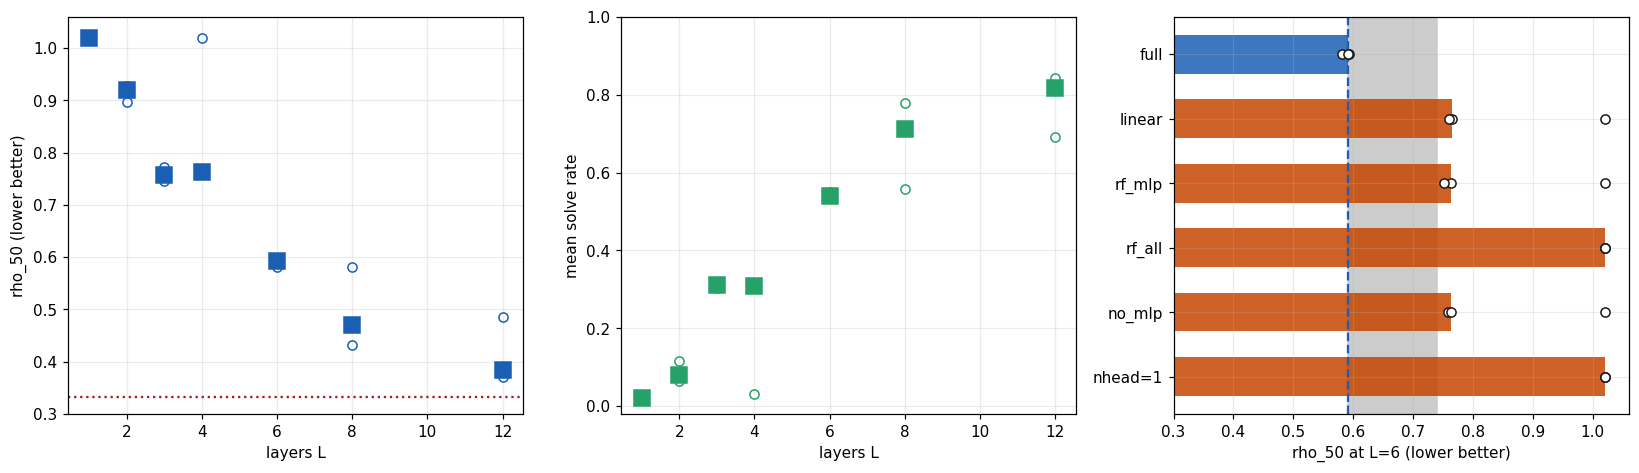

In [5]:
CENSOR = 1.02
fig, axes = plt.subplots(1, 3, figsize=(15, 4.4))
Ls = [L for L in sorted(DEPTH_LADDER) if (L, 4, "full") in rung]
for L in Ls:
    v = rung[(L, 4, "full")]
    pts = [(m["rho50"] if m["flag"] == "ok" else CENSOR) for _, m in v]
    axes[0].plot([L] * len(pts), pts, "o", mfc="none", color="#1a5fb4")
    axes[0].plot([L], [median(pts)], "s", ms=11, color="#1a5fb4")
    axes[1].plot([L] * len(v), [m["mean_solve"] for _, m in v], "o", mfc="none", color="#26a269")
    axes[1].plot([L], [median([m["mean_solve"] for _, m in v])], "s", ms=11, color="#26a269")
axes[0].axhline(0.333, color="#a51d2d", ls=":")
axes[0].set(xlabel="layers L", ylabel="rho_50 (lower better)", ylim=(0.30, CENSOR + 0.04))
axes[1].set(xlabel="layers L", ylabel="mean solve rate", ylim=(-0.02, 1.0))

keys6 = [(6, 4, a) for a in ARCH_AXIS if (6, 4, a) in rung]
if (6, 1, "full") in rung:
    keys6.append((6, 1, "full"))
base = (median([m["rho50"] for _, m in rung[(6, 4, "full")]])
        if (6, 4, "full") in rung and all(m["flag"] == "ok" for _, m in rung[(6, 4, "full")])
        else None)
for i, k in enumerate(keys6):
    v = [(m["rho50"] if m["flag"] == "ok" else CENSOR) for _, m in rung[k]]
    col = ("#1a5fb4" if k == (6, 4, "full")
           else "#26a269" if base is not None and median(v) - base <= s["rho50"] else "#c64600")
    axes[2].barh(len(keys6) - i, median(v), color=col, alpha=0.85, height=0.6)
    axes[2].plot(v, [len(keys6) - i] * len(v), "o", color="0.1", mfc="white", zorder=3)
if base is not None:
    axes[2].axvspan(base, base + s["rho50"], color="0.8", zorder=0)
    axes[2].axvline(base, color="#1a5fb4", ls="--")
axes[2].set_yticks([len(keys6) - i for i in range(len(keys6))])
axes[2].set_yticklabels([(k[2] if k[1] == 4 else "nhead=1") for k in keys6])
axes[2].set(xlabel="rho_50 at L=6 (lower better)", xlim=(0.30, CENSOR + 0.04))
for ax in axes:
    ax.grid(alpha=0.25)
fig.tight_layout()
fig.savefig("/scratch/users/hshunt/spin_gnn/decks/minarch_2026-11-04/nb_axes.png", dpi=120)
print("right panel: dashed line is the unmodified L=6 model, grey band is +s* above it -- "
      "a bar ending inside it is a removal that cost nothing readable")

## 5. rho_50 before and after stripping machinery

This is the question in one table, on the metric of record, at the shallowest
depth where the full model still solves at all three seeds.

**BEFORE** is L=6 with four heads and a trained ReLU MLP. **AFTER** is the same
model with exactly one thing removed. A removal is *free* only if `rho_50` rises
by less than the pooled s\* — anything smaller than that is the seed, not the
architecture.

A censored seed is not a missing number: it is known to be `>0.95`, which is
enough to **order** it above every seed that did cross. So the median survives
the censoring whenever the middle rank is one of the finite values, and a rung
with one censored seed out of three still gets a real `rho_50` and a real delta
rather than the word "censored". `_bound_median` in `scripts/minarch_analysis.py`
does that ordering and is imported here rather than reimplemented, so this table
and the pre-registration output in section 3 cannot disagree. Only a rung whose
*middle* seed is censored stays unreadable, and it is reported as such.

In [6]:
base = (median([m["rho50"] for _, m in rung[(6, 4, "full")]])
        if (6, 4, "full") in rung and all(m["flag"] == "ok" for _, m in rung[(6, 4, "full")])
        else None)
if base is None:
    print("L=6/h4/full has not landed, or is censored -- there is no BEFORE to strip from")
else:
    sp = spread([m["rho50"] for _, m in rung[(6, 4, "full")]])
    print(f"BEFORE  L=6 h=4 full                       rho_50 {base:.3f}  (spread {sp:.3f}, "
          f"mean_solve {median([m['mean_solve'] for _, m in rung[(6, 4, 'full')]]):.4f})")
    print(f"a removal is free iff rho_50 stays below {base + s['rho50']:.3f} "
          f"(= BEFORE + pooled s* {s['rho50']:.4f})\n")
    for k, nm in [((6, 4, "linear"), "linear (no elementwise nonlinearity)"),
                  ((6, 4, "rf_mlp"), "rf_mlp (linear1 frozen at init)"),
                  ((6, 4, "no_mlp"), "no_mlp (attention only)"),
                  ((6, 1, "full"), "nhead=1 (one head, not four)"),
                  ((6, 4, "rf_all"), "rf_all (only the readout trains)")]:
        v = rung.get(k)
        if not v:
            print(f"AFTER   {nm:42s} pending")
            continue
        tr = v[0][1]["n_trainable"]
        msv = median([m["mean_solve"] for _, m in v])
        cens = sum(1 for _, m in v if m["flag"] != "ok")
        bm = _bound_median([(m["rho50"], m["flag"] == "ok") for _, m in v])
        if not bm["bm_readable"]:
            print(f"AFTER   {nm:42s} rho_50 CENSORED ({len(v) - cens}/{len(v)} cross, the "
                  f"MIDDLE seed among them)  mean_solve {msv:.4f}  trainable {tr:,}  -> NOT free")
            continue
        d = bm["rho50_bm"] - base
        # A rung with a censored seed is never "free" even when the readable
        # median sits inside s*: one seed in three never solved at all, and
        # that is a cost the median cannot show.
        verdict = ("COSTS rho_50" if d > s["rho50"]
                   else "FREE" if not cens
                   else "inside s*, but one seed never crossed -> NOT free")
        note = (f"  [{len(v) - cens}/{len(v)} cross; median survives the censoring]"
                if cens else "")
        print(f"AFTER   {nm:42s} rho_50 {bm['rho50_bm']:.3f}  {d:+.3f}  "
              f"mean_solve {msv:.4f}  trainable {tr:,}  -> {verdict}{note}")

BEFORE  L=6 h=4 full                       rho_50 0.592  (spread 0.012, mean_solve 0.5389)
a removal is free iff rho_50 stays below 0.740 (= BEFORE + pooled s* 0.1484)

AFTER   linear (no elementwise nonlinearity)       rho_50 0.765  +0.173  mean_solve 0.3146  trainable 4,899,898  -> COSTS rho_50  [2/3 cross; median survives the censoring]
AFTER   rf_mlp (linear1 frozen at init)            rho_50 0.763  +0.171  mean_solve 0.3104  trainable 3,320,890  -> COSTS rho_50  [2/3 cross; median survives the censoring]
AFTER   no_mlp (attention only)                    rho_50 0.763  +0.171  mean_solve 0.3039  trainable 1,746,490  -> COSTS rho_50  [2/3 cross; median survives the censoring]
AFTER   nhead=1 (one head, not four)               rho_50 CENSORED (0/3 cross, the MIDDLE seed among them)  mean_solve 0.0270  trainable 4,899,898  -> NOT free
AFTER   rf_all (only the readout trains)           rho_50 CENSORED (0/3 cross, the MIDDLE seed among them)  mean_solve 0.0000  trainable 14,906  -> NOT 

### What the completed arch axis says

**The MLP is all-or-nothing.** The three cuts remove three *different* amounts —
`linear` removes only the elementwise nonlinearity, `rf_mlp` removes only the
*training* of the first matrix, `no_mlp` removes the MLP write entirely — and
they cost the same: mean solve 0.3146 / 0.3104 / 0.3039, a spread of **0.0107**
against the L=6 hub's own across-seed spread of **0.0141**. The bar is the hub's
spread and not the pooled s\*, deliberately: `linear` has a seed stuck at the
plateau and therefore *sets* s\* in mean solve, so judging the cuts against it
would be circular. A linear MLP is worth what no MLP is worth, and random
nonlinear features are worth what no MLP is worth. **Only the learned
nonlinearity buys anything, and it is worth about half the depth** — every
stripped L=6 cell lands on the L=3/L=4 rungs of the full ladder.

**rf_all is the one converged negative.** Freezing everything but the readout
leaves an objective that is *convex* in the 14,906 parameters still free, and
its training loss sits at 3.60/3.59 with a last-5-epoch slope of +0.00002.
Everywhere else in this grid "0 of 3 escaped the plateau" has to be hedged as
*did not train at this budget*; here the flat loss on a convex problem means
**converged**, so frozen features with a linear readout genuinely do none of
direct deduction (mean solve 0.0000, 3/3). That hedge still stands for
`nhead=1`, whose objective is not convex and whose 0/3 is a statement about
optimization until stage C's warmup control says otherwise.

**At a matched parameter budget, stripping beats shortening.** Section 5's table
pairs each stripped L=6 rung with the depth rung nearest it in *trainable*
count: `no_mlp` L=6 (1.746M) against full L=2 (1.741M), within 0.3%, scores
0.3039 against 0.0807 — six attention-only layers beat two full ones outright;
`rf_mlp` L=6 (3.321M) against full L=4 (3.320M), within 0.03%, is a tie. So the
minimal frontier here is **attention-only at L=6: 1,746,490 trainable
parameters at rho_50 0.763**, cheaper than full L=3 (2,530,618 at 0.757) for
the same score and a far more tractable object to analyze.

**Caveat carried everywhere:** in all three stripped cells the censored seed *is*
the seed that never escaped the 1.64 plateau, so part of each cost is
trainability rather than representational power, and the quoted +0.17 is the
cost on the seeds that did train.

## 6. Comparison to the previous best on the same eval

Finding 44's 11-02 N=48 fall scan is the only prior run on this exact eval at
this exact budget: same 14-point grid, same instances, same d_model and ff, same
375k steps. The matched cells are L=4, L=8 and L=12 at 240k x 50.

This is a **replication** panel, not an improvement claim. The configuration is
identical and the only change is three seeds instead of one, so the comparison
says how much of finding 44's number was the seed.

In [7]:
prev = {}
for r in load(PREV):
    if (int(r.get("n_train_instances") or 0) == 240000
            and int(r.get("dim_feedforward") or 0) == 1024
            and int(r.get("d_model") or 0) == 256):
        prev.setdefault((r["num_layers"], r["seed"]), []).append(r)
pv = {}
for (L, sd), v in sorted(prev.items()):
    val, flag = rho_50([(x["realized_rho"], x["solve_rate"]) for x in v])
    pv.setdefault(L, []).append(val if flag == "ok" else CENSOR)
def show(xs):
    # A censored seed is a BOUND, not a value; printing the 1.02 sentinel as a
    # number makes a delta computed against it look exact when it is only a
    # lower bound on the improvement.
    return "/".join(">0.95" if x >= CENSOR else f"{x:.3f}" for x in xs)

print(f"{'L':>3} {'11-02 rho_50':>22s} {'this job rho_50':>28s} {'delta of medians':>18s}")
for L in sorted(set(pv) & {k[0] for k in rung if k[1] == 4 and k[2] == 'full'}):
    now = [(m["rho50"] if m["flag"] == "ok" else CENSOR) for _, m in rung[(L, 4, "full")]]
    d, bound = median(now) - median(pv[L]), median(pv[L]) >= CENSOR or median(now) >= CENSOR
    print(f"{L:>3} {show(pv[L]):>22s} {show(now):>28s} "
          f"{('<= ' + format(d, '+.4f')) if bound else format(d, '+.4f'):>18s}")
print(f"\ns* in rho_50 is {s['rho50']:.4f}: a delta smaller than that is the seed, not the run.")
print("'<=' marks a row where one side's median is censored: the 11-02 cell never crossed 50%,")
print("so the true gap is at least as large as shown and the row cannot be read as an exact one.")
print("L=8 is the only fully uncensored match, and its -0.1062 sits INSIDE s* -- a replication.")

  L           11-02 rho_50              this job rho_50   delta of medians
  4                  >0.95            0.760/>0.95/0.763         <= -0.2569
  8            0.565/0.588            0.432/0.581/0.471            -0.1062
 12                  >0.95            0.385/0.370/0.485         <= -0.6350

s* in rho_50 is 0.1484: a delta smaller than that is the seed, not the run.
'<=' marks a row where one side's median is censored: the 11-02 cell never crossed 50%,
so the true gap is at least as large as shown and the row cannot be read as an exact one.
L=8 is the only fully uncensored match, and its -0.1062 sits INSIDE s* -- a replication.


## 7. Controls

1. **Leak.** Every cell trains *and* evaluates with `--shuffle-adj`, read back out
   of each written `config.json` rather than trusted from the command line.
   Findings 16, 17 and 23 are why this is the control that matters most here: a
   minimal architecture that scores well on the leaky task has told us nothing,
   and the smaller the model, the more tempting the decoding shortcut becomes.
2. **Grammar vs deduction.** Finding 25's failure mode is a model that stops
   emitting well-formed traces, which looks like a reasoning gap. Bars: truncation
   below 0.01 and well-formed above 0.99, on bins where solve > 0.1. Broken cells
   are expected to babble and are not held to the bar.
3. **Trainability is not capacity.** A rung whose seeds never got below finding
   44's train-NLL plateau of 1.64 did not *train* at this budget; that is not the
   same as being unable to represent deduction, and it is not written up as such.

In [8]:
leaky = {(r["shuffle_adj"], r["fall"]) for r in rows}
print(f"(shuffle_adj, fall) over all {len(rows)} rows: {leaky}")
budgets = {(r.get("n_train_instances"), r.get("epochs")) for r in rows}
print(f"training budgets: {sorted(budgets)}")
live = [r for r in rows if r["solve_rate"] > 0.1]
over = [r for r in live if r["truncated_rate"] > 0.01 or r["well_formed_rate"] < 0.99]
print(f"{len(live)} live bins: max truncated {max(r['truncated_rate'] for r in live):.4f} (bar 0.01), "
      f"min well_formed {min(r['well_formed_rate'] for r in live):.4f} (bar 0.99), "
      f"{len(over)} breaching")
for r in sorted(over, key=lambda r: -r["truncated_rate"])[:10]:
    print(f"    L={r['num_layers']} {r['arch_mode']} s{r['seed']} rho={r['realized_rho']:.3f} "
          f"solve={r['solve_rate']:.3f} trunc={r['truncated_rate']:.4f} wf={r['well_formed_rate']:.4f}")
print()
for key in all_rungs():
    v = rung.get(key)
    if not v:
        continue
    tr = [history(m["path"])[1] for _, m in v]
    esc = sum(1 for t in tr if t < PLATEAU)
    print(f"{rung_label(*key):16s} train_nll {'/'.join(f'{t:.3f}' for t in tr):26s} "
          f"escapes {esc}/{len(tr)}"
          + ("" if esc else "   <-- DID NOT TRAIN at this budget, NOT 'cannot represent DD'"))

(shuffle_adj, fall) over all 714 rows: {('True', 'True')}
training budgets: [('240000', '50')]
254 live bins: max truncated 0.0200 (bar 0.01), min well_formed 0.9500 (bar 0.99), 22 breaching
    L=12 full s1 rho=0.333 solve=0.365 trunc=0.0200 wf=0.9500
    L=12 full s1 rho=0.396 solve=0.585 trunc=0.0175 wf=0.9600
    L=12 full s1 rho=0.341 solve=0.405 trunc=0.0175 wf=0.9550
    L=8 full s2 rho=0.542 solve=0.720 trunc=0.0125 wf=0.9725
    L=8 full s2 rho=0.438 solve=0.378 trunc=0.0125 wf=0.9675
    L=8 full s2 rho=0.333 solve=0.138 trunc=0.0125 wf=0.9725
    L=12 full s0 rho=0.333 solve=0.290 trunc=0.0100 wf=0.9600
    L=8 full s0 rho=0.333 solve=0.265 trunc=0.0100 wf=0.9825
    L=12 full s1 rho=0.500 solve=0.863 trunc=0.0075 wf=0.9850
    L=12 full s1 rho=0.438 solve=0.718 trunc=0.0075 wf=0.9775

L=12 h=4 full    train_nll 1.494/1.495/1.501          escapes 3/3
L=8  h=4 full    train_nll 1.501/1.518/1.505          escapes 3/3
L=6  h=4 full    train_nll 1.524/1.528/1.530          escape

## 8. Provenance, and what this measurement cannot carry

**Cannot carry.** Three seeds is enough to put a spread on a rung and not enough
for a confidence interval on the spread itself. `rho_50` is one number
summarising 14 binomial bins at n=400, and it censors; where it does, the verdict
moves to `mean_solve` and says so. Nothing here is causal: a small model that
solves the task shows the task does not *need* more machinery, not that this
machinery is what direct deduction looks like inside the larger model. And every
rung is scored at one training budget — a rung that did not escape the plateau is
a statement about 375k steps, not about representability.

In [9]:
print(subprocess.run(["git", "log", "-n", "1", "--format=%H %ad %s", "--date=short"],
                    cwd="/home/users/hshunt/spin_gnn", capture_output=True, text=True).stdout)
print("scan dirs:", *SCANS, sep="\n  ")
for key in all_rungs():
    v = rung.get(key)
    if not v:
        continue
    cfg = json.load(open(os.path.join(v[0][1]["path"], "config.json")))
    print(f"{rung_label(*key):16s} seeds {[sd for sd, _ in v]}  "
          f"arch_mode={cfg.get('arch_mode')} nhead={cfg.get('nhead')} L={cfg.get('num_layers')} "
          f"d_model={cfg.get('d_model')} ff={cfg.get('dim_feedforward')} "
          f"shuffle_adj={cfg.get('shuffle_adj')} fall={cfg.get('fall')} "
          f"steps={cfg.get('n_train_instances')}x{cfg.get('epochs')}")

1f94ad2a371fb2ec2a74faa89360441a87ac6072 2026-11-04 Deck: N3 lands as a converged null, and what a fixed budget buys

scan dirs:
  /scratch/users/hshunt/spin_gnn/sudoku_n48_minarch_2026-11-04
  /scratch/users/hshunt/spin_gnn/sudoku_n48_minarch_L6_2026-11-04
L=12 h=4 full    seeds [0, 1, 2]  arch_mode=full nhead=4 L=12 d_model=256 ff=1024 shuffle_adj=True fall=True steps=240000x50
L=8  h=4 full    seeds [0, 1, 2]  arch_mode=full nhead=4 L=8 d_model=256 ff=1024 shuffle_adj=True fall=True steps=240000x50
L=6  h=4 full    seeds [0, 1, 2]  arch_mode=full nhead=4 L=6 d_model=256 ff=1024 shuffle_adj=True fall=True steps=240000x50
L=4  h=4 full    seeds [0, 1, 2]  arch_mode=full nhead=4 L=4 d_model=256 ff=1024 shuffle_adj=True fall=True steps=240000x50
L=3  h=4 full    seeds [0, 1, 2]  arch_mode=full nhead=4 L=3 d_model=256 ff=1024 shuffle_adj=True fall=True steps=240000x50
L=2  h=4 full    seeds [0, 1, 2]  arch_mode=full nhead=4 L=2 d_model=256 ff=1024 shuffle_adj=True fall=True steps=240000x